# TP Feuilles Plantes — Classification binaire de feuilles (lisse vs denté) avec PyTorch

**Objectif:** Entraîner et évaluer un classifieur binaire `lisse` / `dente` à partir d’images de feuilles, selon ces étapes: préparation des données, définition du modèle, entraînement, évaluation et sauvegarde du meilleur modèle.

**Jeu de données:** Dossier `feuilles_plantes/` comportant deux sous-dossiers (`dente/`, `lisse/`). Chargement via `ImageFolder` pour récupérer automatiquement les étiquettes. Split stratifié **70%/15%/15%** (train/val/test).

**Méthode:** CNN/ResNet entraîné avec `CrossEntropyLoss`, optimiseur `AdamW`, **AMP** pour le calcul mixte précision, **early stopping** sur la perte de validation, suivi **TensorBoard**.

**Métriques:** Accuracy globale et, pour la partie évaluation, **précision, rappel, F1** (binaire et macro) ainsi que **matrices de confusion**.

In [12]:
# === 0) Environnement ===
import torch, torchvision, platform
print("Python :", platform.python_version())
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA dispo :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

torch.backends.cudnn.benchmark = True

Python : 3.12.12
PyTorch: 2.8.0+cu126
TorchVision: 0.23.0+cu126
CUDA dispo : True
GPU : Tesla T4


In [13]:
# === 1) Google Drive & chemins ===
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR  = "/content/drive/MyDrive/feuilles_plantes"
SAVE_PATH = "/content/drive/MyDrive/best_resnet18_lisse_dente.pt"
LOG_DIR   = "/content/drive/MyDrive/feuille_logs"

import os
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(os.path.join(DATA_DIR, "lisse"), exist_ok=True)
os.makedirs(os.path.join(DATA_DIR, "dente"), exist_ok=True)

print("DATA_DIR :", DATA_DIR)
print("SAVE_PATH:", SAVE_PATH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR : /content/drive/MyDrive/feuilles_plantes
SAVE_PATH: /content/drive/MyDrive/best_resnet18_lisse_dente.pt


In [14]:
# === 2) Vérification du dataset ===
import os, glob

def count_imgs(folder):
    exts = (".jpg",".jpeg",".png",".bmp",".webp",".JPG",".PNG",".JPEG")
    return sum(p.lower().endswith(exts) for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True))

classes = [d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))]
print("Classes trouvées :", classes)
for c in sorted(classes):
    print(f"{c:>6} -> {count_imgs(os.path.join(DATA_DIR,c))} images")


Classes trouvées : ['dente', 'lisse']
 dente -> 3126 images
 lisse -> 3401 images


In [15]:
# === 3) Imports & utilitaires ===
import os, random, math, time
from dataclasses import dataclass
from typing import List
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torch.utils.tensorboard import SummaryWriter
from torchvision import datasets, transforms
from tqdm.auto import tqdm

In [16]:
def set_seed(seed: int = 42):
    """
    Fixe les graines principales, et active cuDNN.benchmark pour accélérer
    les convolutions (choisi pour gain de vitesse).
    """
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # laisser cuDNN choisir les kernels les plus rapides
    torch.backends.cudnn.benchmark = True

def accuracy_from_logits(logits: torch.Tensor, targets: torch.Tensor) -> float:
    """top-1 sur le batch."""
    return (logits.argmax(dim=1) == targets).float().mean().item()

@dataclass
class Splits:
    train: Subset
    val: Subset
    test: Subset

def stratified_split(imagefolder_dataset: datasets.ImageFolder,
                     train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, seed=42) -> Splits:
    """
    Découpage stratifié en train/val/test.
    """
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6
    targets = [t for _, t in imagefolder_dataset.samples]
    num_classes = len(imagefolder_dataset.classes)
    per_class_indices: List[List[int]] = [[] for _ in range(num_classes)]
    for idx, t in enumerate(targets):
        per_class_indices[t].append(idx)
    rng = random.Random(seed)
    train_idx, val_idx, test_idx = [], [], []
    for cls_idx_list in per_class_indices:
        rng.shuffle(cls_idx_list)
        n = len(cls_idx_list)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        n_test = n - n_train - n_val
        train_idx += cls_idx_list[:n_train]
        val_idx   += cls_idx_list[n_train:n_train+n_val]
        test_idx  += cls_idx_list[n_train+n_val:]
    rng.shuffle(train_idx); rng.shuffle(val_idx); rng.shuffle(test_idx)
    return Splits(
        train=Subset(imagefolder_dataset, train_idx),
        val=Subset(imagefolder_dataset, val_idx),
        test=Subset(imagefolder_dataset, test_idx),
    )


In [35]:

# === 4) Config ===
set_seed(42)

config = {
    "img_size": 224,
    "batch_size": 32,
    "epochs": 30,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "num_workers": 2,
    "patience": 7,
    "log_dir": LOG_DIR,
    "save_path": SAVE_PATH,
    "seed": 42,
    "use_amp": True,
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Accélération matmul : TF32 + haute précision float32
try:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")
    print("TF32 activé .")
except Exception as e:
    print("TF32 non disponible:", e)


Device: cuda
TF32 activé .


In [18]:
# === 5) Transforms (interpolation bilinéaire)===
from torchvision.transforms import InterpolationMode

normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(config["img_size"], scale=(0.8, 1.0),
                                 interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    normalize,
])

test_tfms = transforms.Compose([
    transforms.Resize((config["img_size"], config["img_size"]),
                      interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    normalize,
])

print("Transforms prêtes.")


Transforms prêtes.


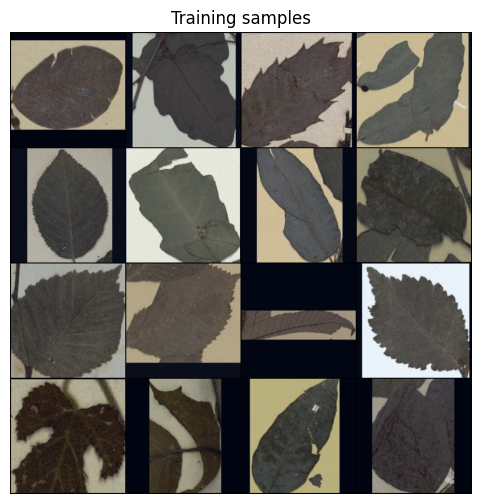

In [36]:

# === 6) Visualisation de quelques exemples ===
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

tmp_dataset = datasets.ImageFolder(root=DATA_DIR, transform=train_tfms)
if len(tmp_dataset) > 0:
    idxs = np.random.choice(len(tmp_dataset), size=min(16, len(tmp_dataset)), replace=False)
    batch = torch.stack([tmp_dataset[i][0] for i in idxs], dim=0)
    grid = make_grid(batch, nrow=4, padding=2, normalize=True)
    plt.figure(figsize=(6,6))
    plt.imshow(grid.permute(1,2,0))
    plt.axis('off')
    plt.title("Training samples")
else:
    print("No images.")


In [20]:
# === 7) Jeux de données & DataLoaders ===
full_train = datasets.ImageFolder(root=DATA_DIR, transform=train_tfms)
classes = full_train.classes
print("Classes détectées :", classes)

splits = stratified_split(full_train, 0.7, 0.15, 0.15, seed=config["seed"])

# Val/Test
val_dataset  = Subset(datasets.ImageFolder(root=DATA_DIR, transform=test_tfms),  splits.val.indices)
test_dataset = Subset(datasets.ImageFolder(root=DATA_DIR, transform=test_tfms), splits.test.indices)
train_dataset = splits.train

print(f"Tailles Train/Val/Test : {len(train_dataset)}/{len(val_dataset)}/{len(test_dataset)}")

# pin memory + prefetch + workers persistants
pin_mem = (device.type == "cuda")
num_workers = config["num_workers"]

loader_kwargs = {
    "num_workers": num_workers,
    "pin_memory": pin_mem,
    "persistent_workers": (num_workers > 0),
}
# prefetch_factor accélère le débit (si num_workers>0)
if num_workers > 0:
    loader_kwargs["prefetch_factor"] = 4
if pin_mem and hasattr(torch.utils.data, "DataLoader"):
    loader_kwargs["pin_memory_device"] = "cuda"

train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True,  **loader_kwargs)
val_loader   = DataLoader(val_dataset,   batch_size=config["batch_size"], shuffle=False, **loader_kwargs)
test_loader  = DataLoader(test_dataset,  batch_size=config["batch_size"], shuffle=False, **loader_kwargs)


Classes détectées : ['dente', 'lisse']
Tailles Train/Val/Test : 4568/978/981


In [21]:
# === 8) Modèle compact + format 'channels_last' ===
class SmallCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, 1, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True),
            nn.Conv2d(32, 32, 3, 1, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, 1, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.SiLU(inplace=True),
            nn.Conv2d(64, 64, 3, 1, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.SiLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, 1, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.SiLU(inplace=True),
            nn.Conv2d(128, 128, 3, 1, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.SiLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, 1, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.SiLU(inplace=True),
            nn.Conv2d(256, 256, 3, 1, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.SiLU(inplace=True),

            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.SiLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SmallCNN(num_classes=2).to(device)

if device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)

# Compilation du modèle (PyTorch 2.x)
try:
    model = torch.compile(model, mode="reduce-overhead")
    print("torch.compile activé.")
except Exception as e:
    print("torch.compile indisponible:", e)

print(model.__class__.__name__, "sur", device)

torch.compile activé.
OptimizedModule sur cuda


In [22]:
# === 9) Entraînement (AMP + EarlyStopping + TensorBoard) ===
optimizer = torch.optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
scaler = torch.amp.GradScaler("cuda", enabled=(device.type=="cuda" and config["use_amp"]))
writer = SummaryWriter(log_dir=config["log_dir"])

best_val_loss = float("inf")
best_state = None
epochs_no_improve = 0

def run_epoch(split, loader):
    is_train = (split == "train")
    model.train() if is_train else model.eval()
    total_loss, total_acc, total_n = 0.0, 0.0, 0
    pbar = tqdm(loader, desc=f"{split}", leave=False, mininterval=0.5)

    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if device.type == "cuda":
            images = images.to(memory_format=torch.channels_last)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            # autocast AMP
            with torch.amp.autocast("cuda", enabled=scaler.is_enabled()):
                logits = model(images)
                loss = F.cross_entropy(logits, labels)

        if is_train:
            if scaler.is_enabled():
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()

        bs = images.size(0)
        total_loss += loss.item() * bs
        total_acc  += accuracy_from_logits(logits, labels) * bs
        total_n    += bs
        pbar.set_postfix(loss=total_loss/total_n, acc=total_acc/total_n)

    return total_loss/total_n, total_acc/total_n

for epoch in range(1, config["epochs"]+1):
    train_loss, train_acc = run_epoch("train", train_loader)
    val_loss, val_acc     = run_epoch("val",   val_loader)

    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Loss/val",   val_loss,   epoch)
    writer.add_scalar("Acc/train",  train_acc,  epoch)
    writer.add_scalar("Acc/val",    val_acc,    epoch)

    print(f"Epoch {epoch:03d}/{config['epochs']} | "
          f"train_loss={train_loss:.4f} acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} acc={val_acc:.4f}")

    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_state = {
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "classes": classes,
            "img_size": config["img_size"],
        }
        torch.save(best_state, config["save_path"])
        epochs_no_improve = 0
        print("✅ Nouveau meilleur modèle sauvegardé ->", config["save_path"])
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= config["patience"]:
            print("⏹️  Arrêt anticipé (early stopping).")
            break

writer.close()

train:   0%|          | 0/143 [00:00<?, ?it/s]

W1021 18:24:57.508000 226 torch/_inductor/utils.py:1436] [0/0] Not enough SMs to use max_autotune_gemm mode
AUTOTUNE addmm(32x128, 32x256, 256x128)
strides: [0, 1], [256, 1], [1, 256]
dtypes: torch.float16, torch.float16, torch.float16
  addmm 0.0717 ms 100.0% 
  bias_addmm 0.1140 ms 62.9% 
SingleProcess AUTOTUNE benchmarking takes 0.0630 seconds and 0.0005 seconds precompiling for 2 choices
AUTOTUNE addmm(32x2, 32x128, 128x2)
strides: [0, 1], [128, 1], [1, 128]
dtypes: torch.float16, torch.float16, torch.float16
  addmm 0.0455 ms 100.0% 
  bias_addmm 0.0737 ms 61.7% 
SingleProcess AUTOTUNE benchmarking takes 0.0353 seconds and 0.0002 seconds precompiling for 2 choices
AUTOTUNE addmm(24x128, 24x256, 256x128)
strides: [0, 1], [256, 1], [1, 256]
dtypes: torch.float16, torch.float16, torch.float16
  addmm 0.0453 ms 100.0% 
  bias_addmm 0.0737 ms 61.5% 
SingleProcess AUTOTUNE benchmarking takes 0.0340 seconds and 0.0003 seconds precompiling for 2 choices
AUTOTUNE addmm(24x2, 24x128, 128x2)

val:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 001/30 | train_loss=0.6297 acc=0.6484 | val_loss=0.6099 acc=0.6677
✅ Nouveau meilleur modèle sauvegardé -> /content/drive/MyDrive/best_resnet18_lisse_dente.pt


train:   0%|          | 0/143 [00:00<?, ?it/s]

...

val:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 023/30 | train_loss=0.1683 acc=0.9330 | val_loss=0.1672 acc=0.9397


train:   0%|          | 0/143 [00:00<?, ?it/s]

val:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 024/30 | train_loss=0.1637 acc=0.9348 | val_loss=0.2160 acc=0.9131
⏹️  Arrêt anticipé (early stopping).


## TESTS & EVALUATIONS

In [23]:
# === 1) TensorBoard (visualize training curves) ===
%load_ext tensorboard
%tensorboard --logdir $LOG_DIR


<IPython.core.display.Javascript object>

In [26]:
# === 2) Inspecter le "meilleur modèle" sauvé ===
st = torch.load(config["save_path"], map_location=device)
print("Meilleur epoch :", st["epoch"])
print("Best val_loss  :", st["val_loss"])
print("Best val_acc   :", st["val_acc"])
print("Classes        :", st["classes"])


Meilleur epoch : 17
Best val_loss  : 0.1663291816026399
Best val_acc   : 0.9386503067484663
Classes        : ['dente', 'lisse']


In [24]:
# === 3) Chargement du modèle et imports ===

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report,
    precision_score, recall_score, f1_score
)
import numpy as np
import matplotlib.pyplot as plt

state = torch.load(config["save_path"], map_location=device)
model.load_state_dict(state["model_state"])
model.eval()

# Classe positive pour les métriques binaires
positive_class_name = "dente" if "dente" in classes else classes[1]
pos_label = classes.index(positive_class_name)
print(f"Classe positive: {positive_class_name}")


Classe positive: dente


In [25]:
# === 4) Prédictions sur l’ensemble de test
test_loss = 0.0
test_correct = 0
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="test"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = F.cross_entropy(logits, labels)

        test_loss += loss.item() * images.size(0)
        pred = logits.argmax(dim=1)

        test_correct += (pred == labels).sum().item()
        y_true.extend(labels.cpu().tolist())
        y_pred.extend(pred.cpu().tolist())

n = len(test_dataset)
test_loss /= max(1, n)
test_acc = test_correct / max(1, n)
print(f"Test - Loss: {test_loss:.4f} | Accuracy: {test_acc:.4f}")


test:   0%|          | 0/31 [00:00<?, ?it/s]

AUTOTUNE addmm(32x2, 32x128, 128x2)
strides: [0, 1], [128, 1], [1, 128]
dtypes: torch.float32, torch.float32, torch.float32
  addmm 0.0448 ms 100.0% 
  bias_addmm 0.0716 ms 62.6% 
SingleProcess AUTOTUNE benchmarking takes 0.0449 seconds and 0.0004 seconds precompiling for 2 choices


Test - Loss: 0.1317 | Accuracy: 0.9388


In [27]:
# === 5) Métriques : précision, rappel, F1
prec_bin = precision_score(y_true, y_pred, pos_label=pos_label, average="binary",  zero_division=0)
rec_bin  = recall_score   (y_true, y_pred, pos_label=pos_label, average="binary",  zero_division=0)
f1_bin   = f1_score       (y_true, y_pred, pos_label=pos_label, average="binary",  zero_division=0)

prec_macro = precision_score(y_true, y_pred, average="macro",    zero_division=0)
rec_macro  = recall_score   (y_true, y_pred, average="macro",    zero_division=0)
f1_macro   = f1_score       (y_true, y_pred, average="macro",    zero_division=0)

print(f"Métriques (classe positive = {positive_class_name})")
print(f"Précision (binaire): {prec_bin:.4f}")
print(f"Rappel (binaire):    {rec_bin:.4f}")
print(f"F1 (binaire):        {f1_bin:.4f}")
print(f"F1 (macro):          {f1_macro:.4f}")


Métriques (classe positive = dente)
Précision (binaire): 0.9680
Rappel (binaire):    0.9021
F1 (binaire):        0.9339
F1 (macro):          0.9385


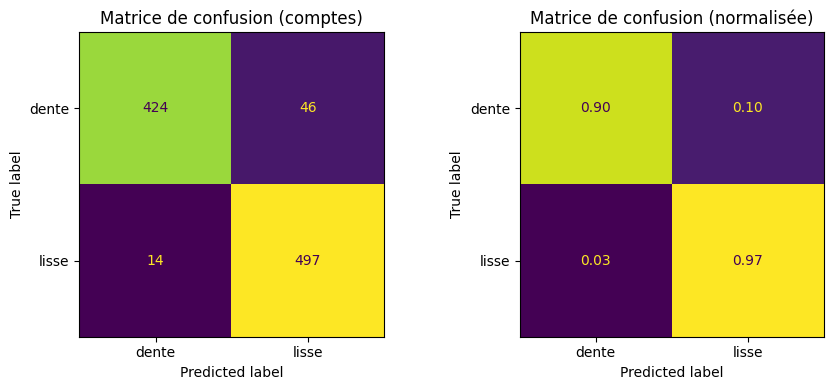

In [28]:
# === 6) Matrices de confusion
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Matrice de confusion (comptes)")

cm_norm = cm.astype(np.float32) / cm.sum(axis=1, keepdims=True).clip(min=1)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=classes)
disp2.plot(ax=axes[1], values_format=".2f", colorbar=False)
axes[1].set_title("Matrice de confusion (normalisée)")

plt.tight_layout()
plt.show()


In [29]:
# === 7) Rapport de classification
print(classification_report(y_true, y_pred, target_names=classes, digits=4, zero_division=0))


              precision    recall  f1-score   support

       dente     0.9680    0.9021    0.9339       470
       lisse     0.9153    0.9726    0.9431       511

    accuracy                         0.9388       981
   macro avg     0.9417    0.9374    0.9385       981
weighted avg     0.9406    0.9388    0.9387       981



In [34]:
# === 8) Résumé
if 'cm' not in globals():
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))

# Verifier l'Accuracy depuis la CM
acc_from_cm = np.trace(cm) / np.sum(cm)

# Métriques binaires (classe positive déjà fixée via pos_label)
prec_bin = precision_score(y_true, y_pred, pos_label=pos_label, average="binary",  zero_division=0)
rec_bin  = recall_score   (y_true, y_pred, pos_label=pos_label, average="binary",  zero_division=0)
f1_bin   = f1_score       (y_true, y_pred, pos_label=pos_label, average="binary",  zero_division=0)

# Moyenne macro
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("=== Résultats finaux ===")
print(f"Accuracy (calcul direct) : {test_acc:.4f}")
print(f"Accuracy (depuis CM)     : {acc_from_cm:.4f}")
print(f"Précision (binaire)      : {prec_bin:.4f}")
print(f"Rappel (binaire)         : {rec_bin:.4f}")
print(f"F1 (binaire)             : {f1_bin:.4f}")
print(f"F1 (macro)               : {f1_macro:.4f}")


=== Résultats finaux ===
Accuracy (calcul direct) : 0.9388
Accuracy (depuis CM)     : 0.9388
Précision (binaire)      : 0.9680
Rappel (binaire)         : 0.9021
F1 (binaire)             : 0.9339
F1 (macro)               : 0.9385


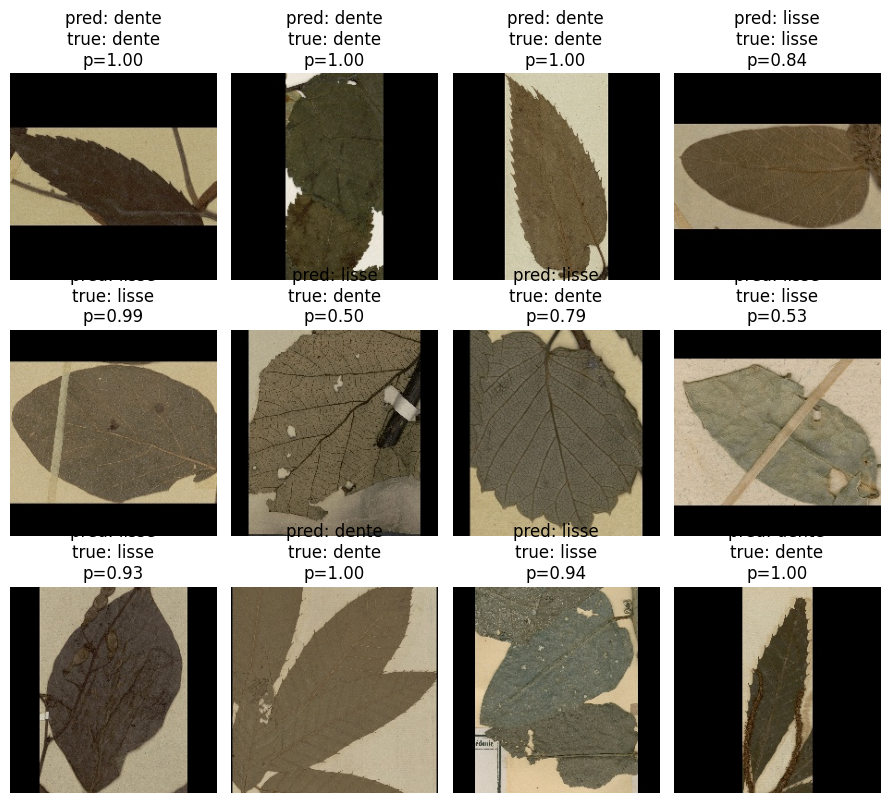

In [32]:
# === 9) Contrôle visuel sur quelques images du test

vis_dataset = datasets.ImageFolder(root=DATA_DIR, transform=test_tfms)
subset_indices = test_dataset.indices if hasattr(test_dataset, "indices") else range(len(test_dataset))
idxs = np.random.choice(len(subset_indices), size=min(12, len(subset_indices)), replace=False)

plt.figure(figsize=(9, 8))
for k, ix in enumerate(idxs, 1):
    true_ix = subset_indices[ix]
    path, true_label = vis_dataset.samples[true_ix]
    img = Image.open(path).convert("RGB")
    x = test_tfms(img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(x)
        pred = logits.argmax(dim=1).item()
        prob = torch.softmax(logits, dim=1)[0, pred].item()
    plt.subplot(3, 4, k)
    plt.imshow(img.resize((224, 224)))
    plt.title(f"pred: {classes[pred]}\ntrue: {classes[true_label]}\np={prob:.2f}")
    plt.axis("off")
plt.tight_layout()
plt.show()


## Conclusion :

**Généralisation:** Les courbes train/val (TensorBoard) montrent une baisse cohérente de la perte de validation au début, puis une stabilisation. L’**early stopping** s’est déclenché après plusieurs époques sans amélioration, et l’accuracy de validation atteint ≈ 0.94 autour du meilleur modèle, ce qui montre une bonne généralisation sans surapprentissage.

**Déséquilibre de classes:** Si une classe est plus fréquente, l’accuracy peut être optimiste ; d’où l’intérêt des métriques **F1** (macro) et de la **matrice de confusion**.

**Limites & pistes d'amelioration :** Inspecter les faux positifs / faux négatifs les plus probables ; équilibrer les batches (sampler) ou ajuster les augmentations. Ou faire du fine-tuning pour améliorer les derniers points de F1.